# 03 - Model results

**Question this notebook answers:** how well can headcount be forecast 15, 30 and 60 minutes ahead, which method is best and by how much, how sure can we be, and what did it cost to compute?

**Where the numbers come from.** Tables are read from `results/*.csv`, written by the scripts in `scripts/` (see `results/README.md`). Sentences quote numbers computed from those tables, not typed in. Two sections (7 and 8) refit the final models to show real predictions and a live forecast.

**Two kinds of score.** *Validation* scores were used to choose settings (tree size, spline options). The *test* set was scored once, at the end, under a protocol written beforehand, so it is the honest estimate. Section 5 compares them.

**Method in one paragraph.** The input is a room's recent headcount history; the output is its headcount one horizon ahead. Seven methods are compared on identical rows: *persistence* ("same as now"), *same time last week*, a *seasonal average* of the time of week, *linear regression*, a *smoothing-spline daily profile*, a *spline hybrid* (daily profile plus a fitted fraction of today's deviation), and a *decision tree* (the main model, from the Week 5 notes). Errors are RMSE and MAE in people.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# find the repository root (works whether Jupyter is started in the root or in notebooks/)
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "occupancy_forecast").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

RAW = ROOT / "data" / "raw"
OCC = RAW / "5occupancySensor_MayToDec2024_9MRows.csv"
ENV = RAW / "5EnvSensor_MayToDec2024_180kRows.csv"
LOOKUP = RAW / "Sensor_ID_and_Locations.xlsx"
CACHE = ROOT / "data" / "processed" / "binned_5min.parquet"
RESULTS = ROOT / "results"

In [2]:
# 5-minute averages of the 9.1M raw readings (computed once, then cached in data/processed/)
if CACHE.exists():
    binned = pd.read_parquet(CACHE)
else:
    from occupancy_forecast.data_loading import resample_occupancy
    binned = resample_occupancy(OCC, 5)
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    binned.to_parquet(CACHE)

def room_names(ids):
    """Readable room names from the location lookup where it has them, else the first 8 characters of the ID."""
    names = {i: i[:8] for i in ids}
    if LOOKUP.exists():
        occ = pd.read_excel(LOOKUP, sheet_name=1)
        for sid, room in zip(occ["SpaceId"], occ["Floor/Room"]):
            if sid in names:
                names[sid] = str(room)
    return names

NAMES = room_names(sorted(binned["floorspaceid"].unique()))
ROOMS = list(NAMES)
COLORS = dict(zip(ROOMS, plt.cm.tab10.colors))
COLOR_OF = {NAMES[r]: COLORS[r] for r in ROOMS}      # colour by room *name*, so a room looks the same in every figure

In [3]:
def R(name):
    return pd.read_csv(RESULTS / name)

LABEL = {"persistence": "persistence", "same_time_last_week": "same time last week", "seasonal_average": "seasonal average",
         "linear_regression": "linear regression", "decision_tree": "decision tree", "spline_hybrid": "spline hybrid",
         "spline_smoothing": "spline profile (smoothing)", "spline_linear": "spline (linear)", "spline_cubic": "spline (cubic)",
         "spline_pchip": "spline (PCHIP)", "spline_akima": "spline (Akima)"}
COL = {"persistence": "#7f7f7f", "same_time_last_week": "#bcbd22", "seasonal_average": "#8c564b", "linear_regression": "#17becf",
       "decision_tree": "#d62728", "spline_hybrid": "#1f77b4", "spline_smoothing": "#9467bd"}

## 1. Choosing the tree: training error against validation error

A deeper tree with smaller leaves fits the training data more closely. Beyond some size it starts fitting noise, and validation error stops improving or rises. This is the under/over-fitting picture from the Week 5 notes.

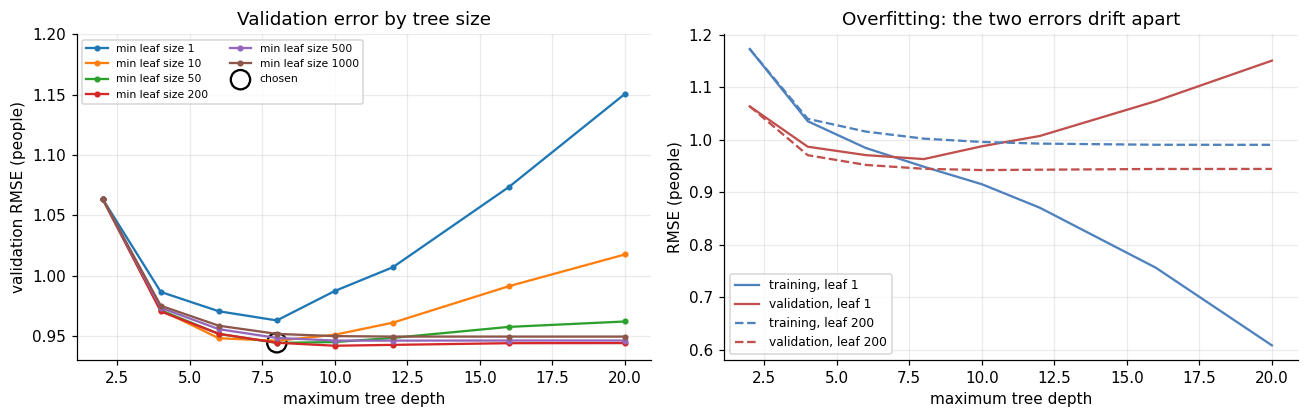

At depth 20 with no leaf limit, training RMSE is **0.61** but validation RMSE is **1.15**, worse than a depth-2 tree. The tree chosen has depth **8** and minimum leaf size **200** (**195** leaves, validation RMSE **0.944**): the simplest tree within 0.5% of the best.

In [4]:
t = R("tuning_h30.csv"); t["max_depth"] = t["max_depth"].astype(int)
sel = t[t["selected"]].iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
for leaf, g in t.groupby("min_samples_leaf"):
    g = g.sort_values("max_depth")
    axes[0].plot(g["max_depth"], g["val_rmse"], marker="o", ms=3, label=f"min leaf size {leaf}")
axes[0].scatter([sel["max_depth"]], [sel["val_rmse"]], s=160, facecolors="none", edgecolors="k", lw=1.5, label="chosen")
axes[0].set_xlabel("maximum tree depth"); axes[0].set_ylabel("validation RMSE (people)"); axes[0].set_ylim(0.93, 1.2)
axes[0].set_title("Validation error by tree size"); axes[0].legend(fontsize=7, ncol=2)
for leaf, style in ((1, "-"), (200, "--")):
    g = t[t["min_samples_leaf"] == leaf].sort_values("max_depth")
    axes[1].plot(g["max_depth"], g["train_rmse"], style, color="#4f81bd", label=f"training, leaf {leaf}")
    axes[1].plot(g["max_depth"], g["val_rmse"], style, color="#c0504d", label=f"validation, leaf {leaf}")
axes[1].set_xlabel("maximum tree depth"); axes[1].set_ylabel("RMSE (people)"); axes[1].set_title("Overfitting: the two errors drift apart")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
deep = t[(t["max_depth"] == 20) & (t["min_samples_leaf"] == 1)].iloc[0]
display(Markdown(f"At depth 20 with no leaf limit, training RMSE is **{deep['train_rmse']:.2f}** but validation RMSE is **{deep['val_rmse']:.2f}**, worse than a "
                 f"depth-2 tree. The tree chosen has depth **{int(sel['max_depth'])}** and minimum leaf size **{int(sel['min_samples_leaf'])}** "
                 f"(**{int(sel['n_leaves'])}** leaves, validation RMSE **{sel['val_rmse']:.3f}**): the simplest tree within 0.5% of the best."))

## 2. How much do the conclusions depend on choices that cannot be checked?

The data has no ground truth for why the sensor goes quiet, so three choices were tested: the forecast horizon, the "quiet gaps are empty rooms" rule, and the 5-minute bin width. All scores here are on the validation set, on measured targets.

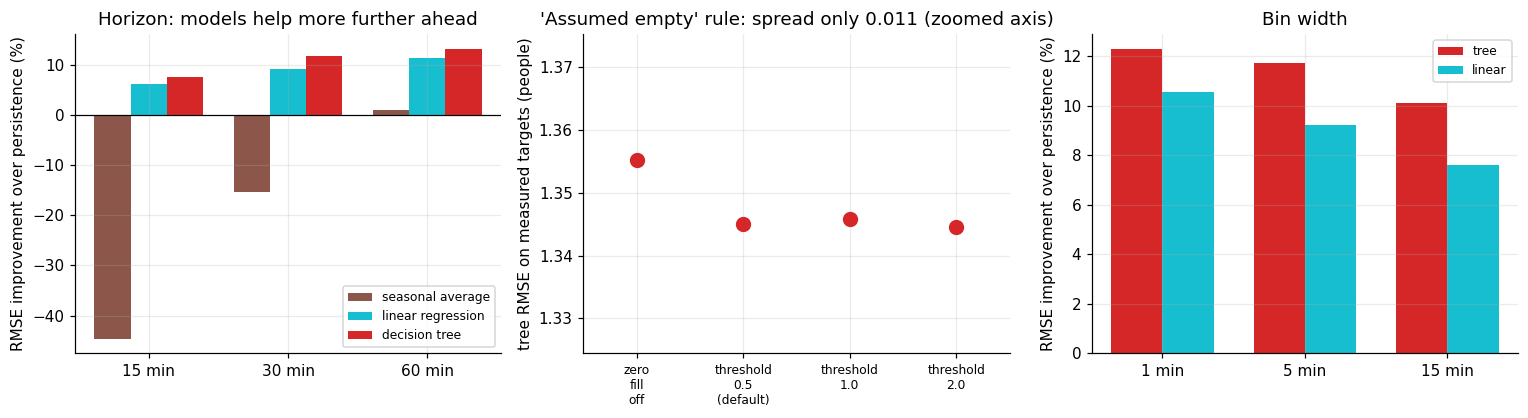

,train_rows,val_rows
gap-rule setting,,
zero_fill_off,243865,76222
threshold_0.5 (default),520600,173513
threshold_1.0,564325,189853
threshold_2.0,597273,200156


Switching the zero-fill rule off removes **53%** of the training rows, yet the tree's RMSE moves by only **0.011** people (0.8%). The forecasts of *measured* headcount do not depend on that assumption. (This cannot show that the filled-in zeros are themselves correct; no ground truth exists for that.)

In [5]:
h = R("sensitivity_horizon.csv"); h = h[h["targets"] == "observed only"]
g = R("sensitivity_gap_rule.csv"); b = R("sensitivity_bin_width.csv")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))

methods = ["seasonal_average", "linear_regression", "decision_tree"]
x = np.arange(3); w = 0.26
for k, m in enumerate(methods):
    v = [h[(h["condition"] == f"h{hh}") & (h["method"] == m)]["rmse_vs_persistence_%"].iloc[0] for hh in (15, 30, 60)]
    axes[0].bar(x + (k - 1) * w, v, w, color=COL[m], label=LABEL[m])
axes[0].axhline(0, color="k", lw=0.8); axes[0].set_xticks(x); axes[0].set_xticklabels(["15 min", "30 min", "60 min"])
axes[0].set_ylabel("RMSE improvement over persistence (%)"); axes[0].set_title("Horizon: models help more further ahead"); axes[0].legend(fontsize=8)

tree = g[g["method"] == "decision_tree"].set_index("condition")["rmse"]
axes[1].plot(range(len(tree)), tree.values, "o", ms=9, color="#d62728")
axes[1].set_xticks(range(len(tree))); axes[1].set_xticklabels([c.replace(" (default)", "\n(default)").replace("_", "\n") for c in tree.index], fontsize=8)
lo, hi = tree.min(), tree.max(); axes[1].set_ylim(lo - 0.02, hi + 0.02); axes[1].set_xlim(-0.5, len(tree) - 0.5)
axes[1].set_ylabel("tree RMSE on measured targets (people)"); axes[1].set_title(f"'Assumed empty' rule: spread only {hi - lo:.3f} (zoomed axis)")

xb = np.arange(len(b))
axes[2].bar(xb - 0.18, b["tree_vs_persistence_%"], 0.36, color="#d62728", label="tree")
axes[2].bar(xb + 0.18, b["linear_vs_persistence_%"], 0.36, color="#17becf", label="linear")
axes[2].set_xticks(xb); axes[2].set_xticklabels([f"{m} min" for m in b["bin_minutes"]])
axes[2].set_ylabel("RMSE improvement over persistence (%)"); axes[2].set_title("Bin width"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
sizes = R("sensitivity_gap_rule_sizes.csv").rename(columns={"Unnamed: 0": "gap-rule setting"}).set_index("gap-rule setting")
display(sizes)
display(Markdown(f"Switching the zero-fill rule off removes **{1 - sizes['train_rows'].iloc[0] / sizes['train_rows'].iloc[1]:.0%}** of the training rows, yet "
                 f"the tree's RMSE moves by only **{hi - lo:.3f}** people ({(hi - lo) / lo:.1%}). The forecasts of *measured* headcount do not depend on that assumption. "
                 "(This cannot show that the filled-in zeros are themselves correct; no ground truth exists for that.)"))

## 3. Spline models: does a smooth curve beat a stepwise average?

Five spline constructions from the Week 3.4 notes fit a smooth curve of headcount against time of day. A sixth model adds persistence of today's deviation. Scores are on validation data, 30 minutes ahead, measured targets.

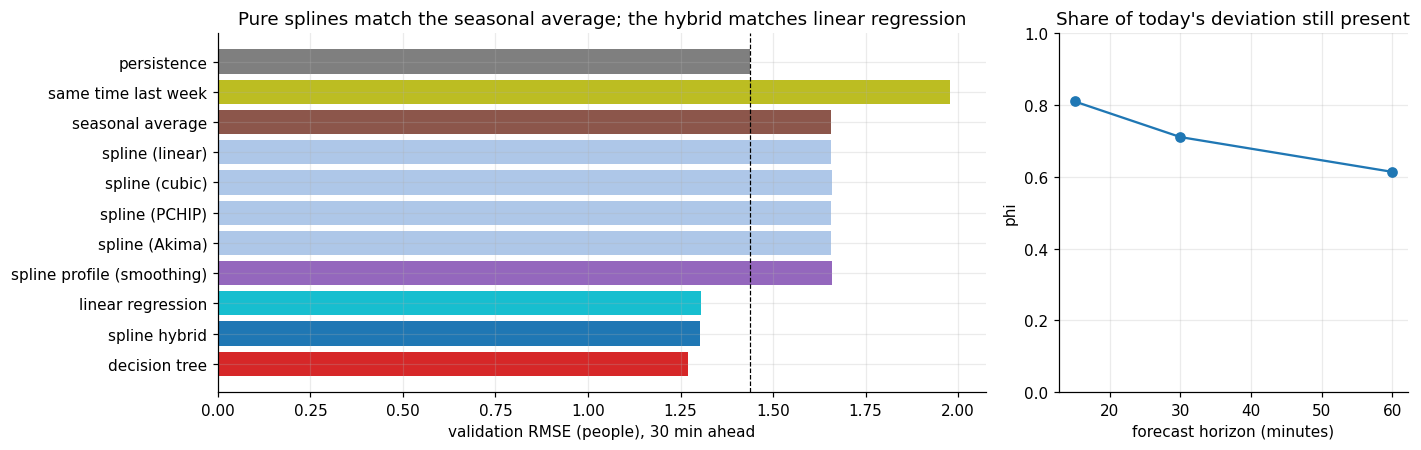

The five pure spline types differ by only **0.002** RMSE, and all match the seasonal average (**1.658**): a smooth curve of time of day cannot add what the data lacks. Adding persistence (the hybrid) gives **1.304**, about the same as linear regression (**1.305**). The fitted persistence fraction falls from **0.81** at 15 minutes to **0.61** at 60.

In [6]:
s = R("spline_comparison.csv"); s30 = s[(s["targets"] == "observed only") & (s["condition"] == "h30")].set_index("method")
order = ["persistence", "same_time_last_week", "seasonal_average", "spline_linear", "spline_cubic", "spline_pchip", "spline_akima",
         "spline_smoothing", "linear_regression", "spline_hybrid", "decision_tree"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})
vals = s30.loc[order, "rmse"]
axes[0].barh([LABEL[m] for m in order][::-1], vals.values[::-1], color=[COL.get(m, "#aec7e8") for m in order][::-1])
axes[0].axvline(s30.loc["persistence", "rmse"], color="k", ls="--", lw=0.8)
axes[0].set_xlabel("validation RMSE (people), 30 min ahead"); axes[0].set_title("Pure splines match the seasonal average; the hybrid matches linear regression")
phi = R("spline_hybrid_phi.csv")
axes[1].plot(phi["horizon_min"], phi["phi"], marker="o", color="#1f77b4"); axes[1].set_ylim(0, 1)
axes[1].set_xlabel("forecast horizon (minutes)"); axes[1].set_ylabel("phi"); axes[1].set_title("Share of today's deviation still present")
plt.tight_layout(); plt.show()
pure = s30.loc[["spline_linear", "spline_cubic", "spline_pchip", "spline_akima", "spline_smoothing"], "rmse"]
display(Markdown(f"The five pure spline types differ by only **{pure.max() - pure.min():.3f}** RMSE, and all match the seasonal average "
                 f"(**{s30.loc['seasonal_average', 'rmse']:.3f}**): a smooth curve of time of day cannot add what the data lacks. "
                 f"Adding persistence (the hybrid) gives **{s30.loc['spline_hybrid', 'rmse']:.3f}**, about the same as linear regression (**{s30.loc['linear_regression', 'rmse']:.3f}**). "
                 f"The fitted persistence fraction falls from **{phi['phi'].iloc[0]:.2f}** at 15 minutes to **{phi['phi'].iloc[-1]:.2f}** at 60."))

## 4. What it costs: runtime, data needs and memory

The brief asks for the performance of the solution to be analysed and the final design justified. Tree tuning was the one slow step, so that is where the optimisation went.

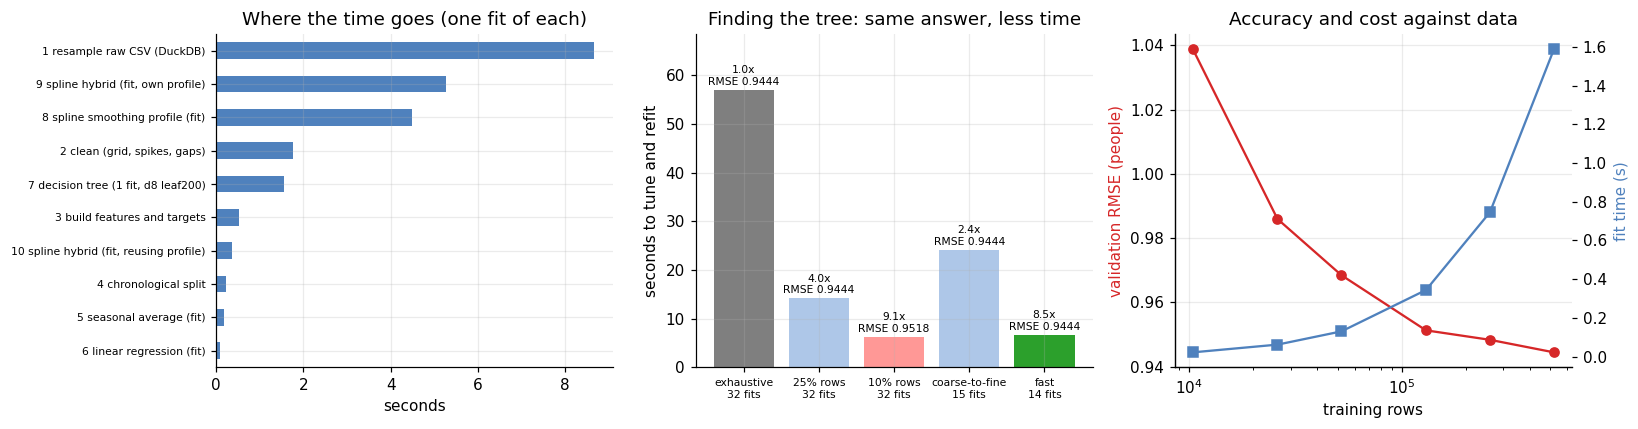

- The fast tuner picks the **same tree** (depth 8, leaf 200) as the exhaustive search in **6.7 s instead of 57.0 s** (8.5x faster). Using only 10% of the rows is faster still but picks a worse tree (+0.78% RMSE).
- A quarter of the training rows gets within **0.7%** of the full-data error, and fit time grows almost in proportion to rows.
- The left panel shows one fit of each stage; **tuning the tree means many fits** (32 in the exhaustive search, **57 s**), which is why that is where the optimisation went.
- These changes make the computation faster; they do not change the model or its accuracy.

,rows,seconds,peak_rss_mb,speedup_vs_pandas
method,,,,
DuckDB (selected),1000000,1.0,246.2,6.2
chunked pandas (baseline),1000000,6.5,376.5,1.0
"duckdb (measured, full file)",9091732,8.8,431.2,6.7


In [7]:
st = R("stage_timings.csv").set_index("stage"); ts = R("tuning_strategies.csv").set_index("strategy"); lc = R("learning_curve.csv")
fig, axes = plt.subplots(1, 3, figsize=(15, 4.0))
st["seconds"].sort_values().plot.barh(ax=axes[0], color="#4f81bd"); axes[0].set_xlabel("seconds"); axes[0].set_ylabel("")
axes[0].set_title("Where the time goes (one fit of each)"); axes[0].tick_params(axis="y", labelsize=7)

ts = ts.loc[["exhaustive", "subsample25", "subsample10", "coarse_to_fine", "fast"]]
axes[1].bar(range(len(ts)), ts["total_seconds"], color=["#7f7f7f", "#aec7e8", "#ff9896", "#aec7e8", "#2ca02c"])
for i, (name, r) in enumerate(ts.iterrows()):
    axes[1].text(i, r["total_seconds"] + 1, f"{r['speedup_vs_exhaustive']:.1f}x\nRMSE {r['val_rmse']:.4f}", ha="center", fontsize=7)
axes[1].set_xticks(range(len(ts))); axes[1].set_xticklabels(["exhaustive\n32 fits", "25% rows\n32 fits", "10% rows\n32 fits", "coarse-to-fine\n15 fits", "fast\n14 fits"], fontsize=7)
axes[1].set_ylim(0, ts["total_seconds"].max() * 1.2); axes[1].set_ylabel("seconds to tune and refit"); axes[1].set_title("Finding the tree: same answer, less time")

ax = axes[2]; ax.plot(lc["train_rows"], lc["val_rmse"], marker="o", color="#d62728"); ax.set_xscale("log")
ax.set_xlabel("training rows"); ax.set_ylabel("validation RMSE (people)", color="#d62728"); ax.set_title("Accuracy and cost against data")
ax2 = ax.twinx(); ax2.plot(lc["train_rows"], lc["fit_seconds"], marker="s", color="#4f81bd"); ax2.set_ylabel("fit time (s)", color="#4f81bd"); ax2.grid(False)
plt.tight_layout(); plt.show()
fast, exh = ts.loc["fast"], ts.loc["exhaustive"]
quarter = lc.iloc[(lc["fraction"] - 0.25).abs().argmin()]
display(Markdown(f"- The fast tuner picks the **same tree** (depth {int(fast['max_depth'])}, leaf {int(fast['min_samples_leaf'])}) as the exhaustive search in "
                 f"**{fast['total_seconds']:.1f} s instead of {exh['total_seconds']:.1f} s** ({fast['speedup_vs_exhaustive']:.1f}x faster). Using only 10% of the rows is faster still but picks a worse tree "
                 f"({ts.loc['subsample10', 'val_rmse_vs_exhaustive_%']:+.2f}% RMSE).\n"
                 f"- A quarter of the training rows gets within **{quarter['val_rmse_vs_full_%']:.1f}%** of the full-data error, and fit time grows almost in proportion to rows.\n"
                 f"- The left panel shows one fit of each stage; **tuning the tree means many fits** (32 in the exhaustive search, **{exh['total_seconds']:.0f} s**), which is why that is where the optimisation went.\n"
                 "- These changes make the computation faster; they do not change the model or its accuracy."))
lo_ = R("loader_comparison.csv").set_index("method")
display(lo_[["rows", "seconds", "peak_rss_mb", "speedup_vs_pandas"]].round(1).rename(index={"duckdb": "DuckDB (selected)", "pandas": "chunked pandas (baseline)"}))

## 5. The test set: the honest estimate

Opened once, after every decision was final. All methods are scored on identical rows whose targets were actually measured; the intervals come from resampling whole room-days (neighbouring 5-minute errors are strongly correlated, so resampling rows would make the intervals falsely narrow).

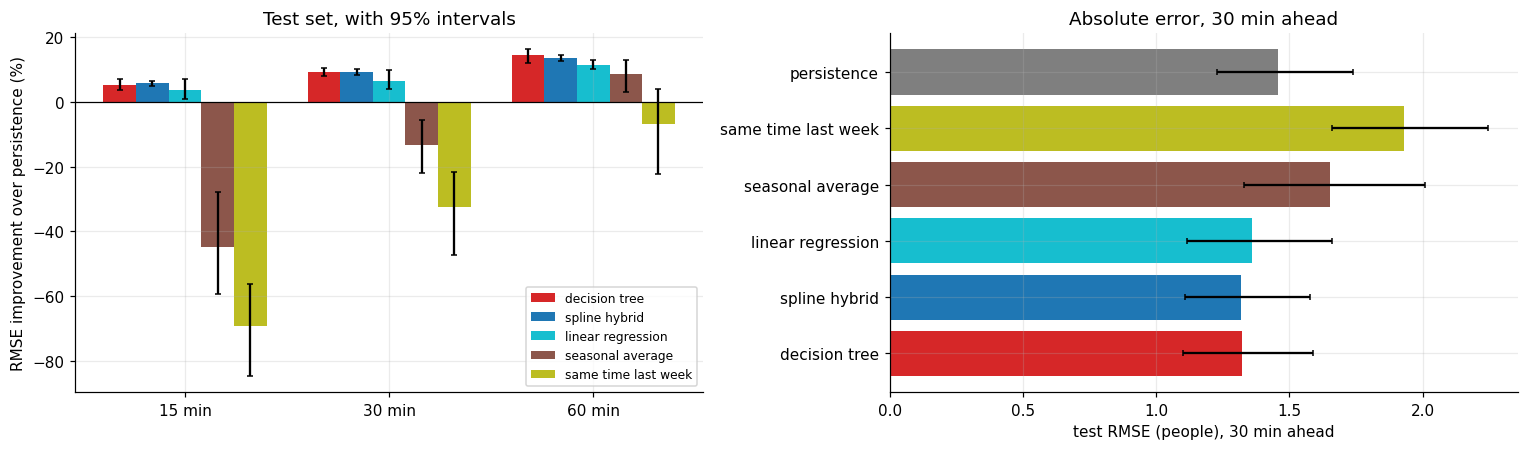

- **15 min:** tree **5.4%** better than persistence (95% interval 3.7 to 7.3); spline hybrid 5.9% (5.0 to 6.7); tree vs linear regression +1.5% (-0.9 to +3.5).
- **30 min:** tree **9.2%** better than persistence (95% interval 8.0 to 10.6); spline hybrid 9.4% (8.5 to 10.2); tree vs linear regression +2.8% (+0.5 to +4.5).
- **60 min:** tree **14.5%** better than persistence (95% interval 12.2 to 16.3); spline hybrid 13.6% (12.8 to 14.4); tree vs linear regression +3.3% (+1.3 to +5.0).

**Validation was optimistic:** at 30 minutes validation gave a 11.7% improvement; the test set gives 9.2%. That is expected, since settings were chosen on validation and the later test period is a little different. The tree and the spline hybrid are statistically indistinguishable on RMSE (their intervals overlap almost completely); the tree has the lower MAE at all three horizons.

*How to read the two panels:* in the left panel each interval is for the **difference from persistence**, measured on the same days, so it is narrow. In the right panel each interval is for a method's **own** RMSE, which is wide because every method shares the same easy and hard days; those intervals overlap even where the left panel shows a clear difference. Compare methods using the left panel.

,rows,rmse,rmse_lo,rmse_hi,mae,improvement_pct
method,,,,,,
persistence,74335,1.457,1.229,1.739,0.778,0.000
same time last week,74335,1.930,1.659,2.246,1.070,-32.463
seasonal average,74335,1.651,1.329,2.008,0.875,-13.302
linear regression,74335,1.361,1.115,1.660,0.695,6.564
spline profile (smoothing),74335,1.650,1.328,2.007,0.874,-13.253
spline hybrid,74335,1.320,1.108,1.577,0.716,9.427
decision tree,74335,1.323,1.103,1.589,0.694,9.217


In [8]:
T = R("final_test_main.csv"); T = T[T["subset"] == "observed"]
imp = [m for m in ["decision_tree", "spline_hybrid", "linear_regression", "seasonal_average", "same_time_last_week"]]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
x = np.arange(3); w = 0.16
for k, m in enumerate(imp):
    d = T[T["method"] == m].sort_values("horizon")
    yerr = np.vstack([d["improvement_pct"] - d["improvement_lo"], d["improvement_hi"] - d["improvement_pct"]])
    axes[0].bar(x + (k - 2) * w, d["improvement_pct"], w, yerr=yerr, capsize=2, color=COL[m], label=LABEL[m])
axes[0].axhline(0, color="k", lw=0.8); axes[0].set_xticks(x); axes[0].set_xticklabels(["15 min", "30 min", "60 min"])
axes[0].set_ylabel("RMSE improvement over persistence (%)"); axes[0].set_title("Test set, with 95% intervals"); axes[0].legend(fontsize=8)

d30 = T[T["horizon"] == 30].set_index("method").loc[["persistence", "same_time_last_week", "seasonal_average", "linear_regression", "spline_hybrid", "decision_tree"]]
yerr = np.vstack([d30["rmse"] - d30["rmse_lo"], d30["rmse_hi"] - d30["rmse"]])
axes[1].barh([LABEL[m] for m in d30.index][::-1], d30["rmse"][::-1], xerr=yerr[:, ::-1], capsize=2, color=[COL[m] for m in d30.index][::-1])
axes[1].set_xlabel("test RMSE (people), 30 min ahead"); axes[1].set_title("Absolute error, 30 min ahead")
plt.tight_layout(); plt.show()

tree = T[T["method"] == "decision_tree"].set_index("horizon"); hyb = T[T["method"] == "spline_hybrid"].set_index("horizon")
V = R("final_test_vs_linear.csv"); V = V[(V["subset"] == "observed") & (V["method"] == "decision_tree")].set_index("horizon")
val30 = R("sensitivity_horizon.csv"); val30 = val30[(val30["targets"] == "observed only") & (val30["condition"] == "h30") & (val30["method"] == "decision_tree")]["rmse_vs_persistence_%"].iloc[0]
rows = "\n".join(f"- **{hh} min:** tree **{tree.loc[hh, 'improvement_pct']:.1f}%** better than persistence (95% interval {tree.loc[hh, 'improvement_lo']:.1f} to {tree.loc[hh, 'improvement_hi']:.1f}); "
                  f"spline hybrid {hyb.loc[hh, 'improvement_pct']:.1f}% ({hyb.loc[hh, 'improvement_lo']:.1f} to {hyb.loc[hh, 'improvement_hi']:.1f}); "
                  f"tree vs linear regression {V.loc[hh, 'improvement_vs_linear_pct']:+.1f}% ({V.loc[hh, 'improvement_lo']:+.1f} to {V.loc[hh, 'improvement_hi']:+.1f})." for hh in (15, 30, 60))
display(Markdown(rows + f"\n\n**Validation was optimistic:** at 30 minutes validation gave a {val30:.1f}% improvement; the test set gives {tree.loc[30, 'improvement_pct']:.1f}%. "
                 "That is expected, since settings were chosen on validation and the later test period is a little different. "
                 "The tree and the spline hybrid are statistically indistinguishable on RMSE (their intervals overlap almost completely); the tree has the lower MAE at all three horizons.\n\n"
                 "*How to read the two panels:* in the left panel each interval is for the **difference from persistence**, measured on the same days, so it is narrow. "
                 "In the right panel each interval is for a method's **own** RMSE, which is wide because every method shares the same easy and hard days; "
                 "those intervals overlap even where the left panel shows a clear difference. Compare methods using the left panel."))
display(T[T["horizon"] == 30].set_index("method")[["rows", "rmse", "rmse_lo", "rmse_hi", "mae", "improvement_pct"]].round(3).rename(index=LABEL))

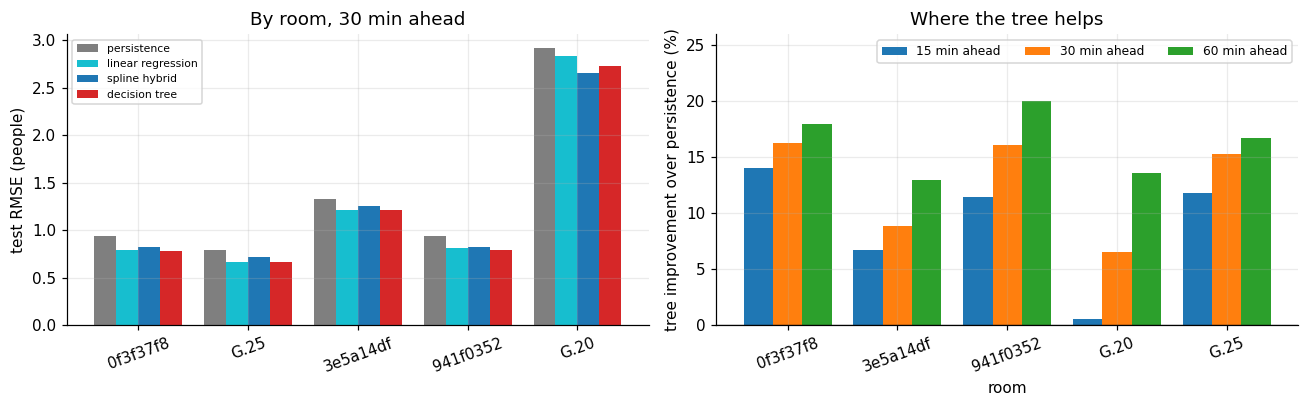

Room **G.20** is by far the hardest (persistence RMSE **2.92** at 30 minutes against **1.00** for the others on average), and the tree gains only **6.5%** there; the other rooms gain **9% to 16%**. The overall improvement hides a large difference between rooms.

**Look-ahead check.** The cleaning step interpolates short gaps using the next reading and caps spikes with a window that looks ahead; **29%** of test rows have such a value in the previous hour, which a live system could not have. On the strictly causal rows the tree's 30-minute improvement is **14.5%** (against 9.2% overall), so look-ahead is not what produces the gain. Those rows are a selected, more regular subset, so this shows the gain is not inflated, not that it is exactly that size.

In [9]:
room = R("final_test_by_room.csv"); sz = R("final_test_sizes.csv")
r30 = room[room["horizon"] == 30].set_index("room")
rid_name = {v[:8]: NAMES[v] for v in ROOMS}
r30.index = [rid_name.get(i, i) for i in r30.index]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
cols = {"rmse_persistence": "persistence", "rmse_linear_regression": "linear regression",
        "rmse_spline_hybrid": "spline hybrid", "rmse_decision_tree": "decision tree"}
r30[list(cols)].rename(columns=cols).plot.bar(
    ax=axes[0], color=[COL["persistence"], COL["linear_regression"], COL["spline_hybrid"], COL["decision_tree"]], width=0.8)
axes[0].set_ylabel("test RMSE (people)"); axes[0].set_title("By room, 30 min ahead"); axes[0].tick_params(axis="x", rotation=20)
axes[0].legend(fontsize=7)
piv = room.assign(room=room["room"].map(lambda i: rid_name.get(i, i))).pivot(index="room", columns="horizon", values="tree_vs_persistence_%")
piv.columns = [f"{c} min ahead" for c in piv.columns]
piv.plot.bar(ax=axes[1], width=0.8); axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_ylabel("tree improvement over persistence (%)"); axes[1].set_title("Where the tree helps"); axes[1].tick_params(axis="x", rotation=20)
axes[1].set_ylim(0, piv.max().max() * 1.3); axes[1].legend(fontsize=8, ncol=3, loc="upper right")
plt.tight_layout(); plt.show()
worst = r30["rmse_persistence"].idxmax()
display(Markdown(f"Room **{worst}** is by far the hardest (persistence RMSE **{r30.loc[worst, 'rmse_persistence']:.2f}** at 30 minutes against **{r30['rmse_persistence'].drop(worst).mean():.2f}** for the others on average), "
                 f"and the tree gains only **{r30.loc[worst, 'tree_vs_persistence_%']:.1f}%** there; the other rooms gain **{r30['tree_vs_persistence_%'].drop(worst).min():.0f}% to {r30['tree_vs_persistence_%'].drop(worst).max():.0f}%**. "
                 "The overall improvement hides a large difference between rooms."))
display(Markdown(f"**Look-ahead check.** The cleaning step interpolates short gaps using the next reading and caps spikes with a window that looks ahead; "
                 f"**{sz[sz['horizon'] == 30]['share_rows_using_lookahead'].iloc[0]:.0%}** of test rows have such a value in the previous hour, which a live system could not have. "
                 f"On the strictly causal rows the tree's 30-minute improvement is "
                 f"**{R('final_test_main.csv').query('horizon == 30 and subset == \"causal\" and method == \"decision_tree\"')['improvement_pct'].iloc[0]:.1f}%** "
                 f"(against {tree.loc[30, 'improvement_pct']:.1f}% overall), so look-ahead is not what produces the gain. "
                 "Those rows are a selected, more regular subset, so this shows the gain is not inflated, not that it is exactly that size."))

## 6. Fitting the final models

Sections 7 and 8 need real predictions, so the final models are refitted here exactly as `scripts/final_evaluation.py` does: tree settings chosen on training and validation rows with the fast tuner, then every learned method refitted on both.

In [10]:
from occupancy_forecast.cleaning import clean_occupancy
from occupancy_forecast.features import build_supervised_dataset
from occupancy_forecast.final import fit_final_models, predict_methods
from occupancy_forecast.validation import chronological_split

clean = clean_occupancy(binned)
train, val, test = chronological_split(build_supervised_dataset(clean, horizon_minutes=30))
models = fit_final_models(train, val, 30)
preds = predict_methods(models, test)
print(f"tree {models.best_params}, {models.tree.get_n_leaves()} leaves, fitted on {models.tree.tree_.n_node_samples[0]:,} rows")

tree {'max_depth': 8, 'min_samples_leaf': 200}, 206 leaves, fitted on 694,113 rows


## 7. What the forecasts look like

Three days of the test period for one room: the actual headcount 30 minutes after each forecast time (grey, measured targets only) against persistence, the spline hybrid and the tree.

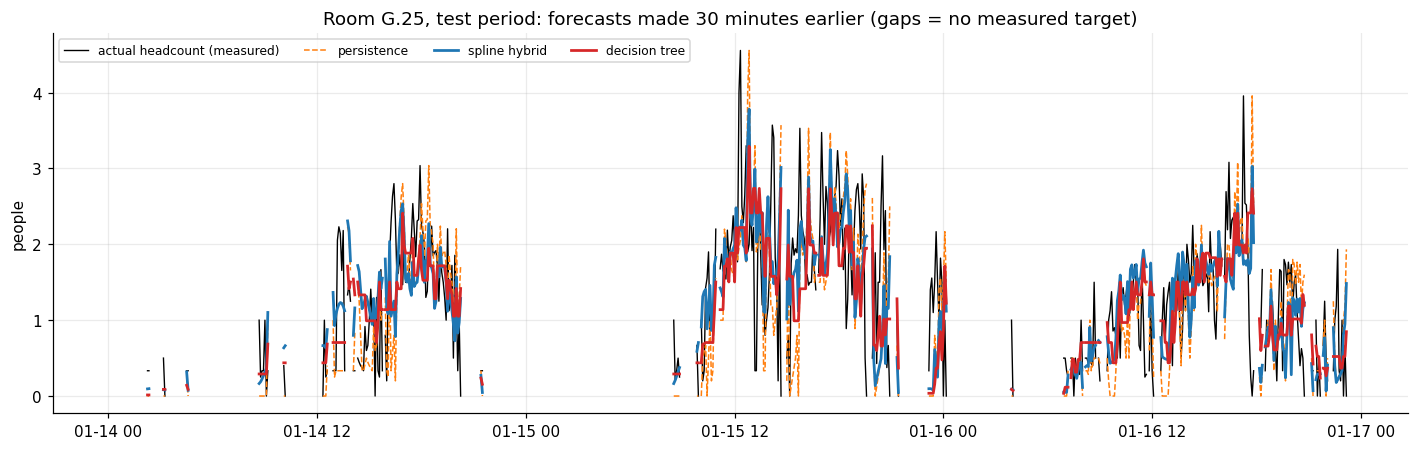

RMSE over these three days: persistence **0.92**, spline hybrid **0.79**, decision tree **0.76**. The tree and hybrid follow the broad rises and falls of the day; neither anticipates sudden short-lived spikes, which are not predictable from past headcount.

In [11]:
rid = next((r for r in ROOMS if NAMES[r] == "G.25"), ROOMS[0])
mine = test.assign(persistence=preds["persistence"], spline_hybrid=preds["spline_hybrid"], decision_tree=preds["decision_tree"])
mine = mine[(mine["floorspaceid"] == rid) & (mine["target_fill_status"] == "observed")]
daily = mine.groupby(mine["target_timestamp"].dt.normalize())["target"].mean()
best_start = daily.rolling(3).mean().idxmax() - pd.Timedelta(days=2)
win = mine[(mine["target_timestamp"] >= best_start) & (mine["target_timestamp"] < best_start + pd.Timedelta(days=3))]

grid_t = pd.date_range(best_start, best_start + pd.Timedelta(days=3), freq="5min", inclusive="left")
plot = win.set_index("target_timestamp").reindex(grid_t)          # empty bins stay NaN, so lines break instead of bridging gaps
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.plot(plot.index, plot["target"], color="black", lw=0.9, label="actual headcount (measured)")
ax.plot(plot.index, plot["persistence"], color="#ff7f0e", lw=1.0, ls="--", label=LABEL["persistence"])
for m in ("spline_hybrid", "decision_tree"):
    ax.plot(plot.index, plot[m], color=COL[m], lw=1.8, label=LABEL[m])
ax.set_ylabel("people"); ax.set_title(f"Room {NAMES[rid]}, test period: forecasts made 30 minutes earlier (gaps = no measured target)"); ax.legend(fontsize=8, ncol=4, loc="upper left")
plt.tight_layout(); plt.show()
w_rmse = {m: float(np.sqrt(((win[m] - win["target"]) ** 2).mean())) for m in ("persistence", "spline_hybrid", "decision_tree")}
display(Markdown("RMSE over these three days: " + ", ".join(f"{LABEL[m]} **{v:.2f}**" for m, v in w_rmse.items()) +
                 ". The tree and hybrid follow the broad rises and falls of the day; neither anticipates sudden short-lived spikes, which are not predictable from past headcount."))

## 8. The callable function on raw sensor readings

`forecast_headcount()` takes raw readings in the same format as the sensor CSV (room, headcount, timestamp with UTC offset) and returns a forecast per room. It uses the same feature code as training. Here it is given the 24 hours of raw readings before one test-set time, read straight from the CSV.

In [12]:
import duckdb
from occupancy_forecast.forecast import forecast_headcount, make_bundle

bundle = make_bundle(models)
rooms_per_time = test.groupby("timestamp")["floorspaceid"].nunique()
cand = win["timestamp"][win["timestamp"].dt.hour == 11]
t_live = next((t for t in cand if rooms_per_time.get(t, 0) == len(ROOMS)), cand.iloc[0] if len(cand) else win["timestamp"].iloc[0])

if OCC.exists():
    d0, d1 = (t_live - pd.Timedelta(days=1)).date(), t_live.date()
    raw = duckdb.connect().execute(
        f"""SELECT floorspaceid, headcount, collecteddate FROM read_csv_auto('{OCC}')
            WHERE CAST(collecteddate AT TIME ZONE 'Australia/Melbourne' AS DATE) BETWEEN DATE '{d0}' AND DATE '{d1}'""").fetchdf()
    local = raw["collecteddate"].dt.tz_convert("Australia/Melbourne").dt.tz_localize(None)
    raw = raw[(local >= t_live - pd.Timedelta(hours=24)) & (local < t_live + pd.Timedelta(minutes=5))]
    out = forecast_headcount(raw, bundle, as_of=t_live)
    out["room"] = out["floorspaceid"].map(NAMES)
    batch = test[test["timestamp"] == t_live].set_index("floorspaceid")
    out["batch_pipeline"] = out["floorspaceid"].map(lambda r: models.tree.predict(batch.loc[[r], models.features])[0] if r in batch.index else np.nan)
    out["actual_later"] = out["floorspaceid"].map(batch["target"])
    absent = [NAMES[r] for r in ROOMS if r not in set(raw["floorspaceid"])]
    display(Markdown(f"Input: **{len(raw):,}** raw readings for {raw['floorspaceid'].nunique()} rooms, up to the end of the bin starting **{t_live:%Y-%m-%d %H:%M}** (Melbourne time)."
                     + (f" Room {', '.join(absent)} has no readings in this period (its data ends earlier), so it is not forecast." if absent else "")))
    display(out[["room", "as_of", "forecast_for", "predicted_headcount", "current_headcount", "batch_pipeline", "actual_later", "status", "outside_training_range"]].round(2).set_index("room"))
    display(Markdown("The live forecast matches the batch pipeline for the same time. `actual_later` is the headcount that was then recorded for the forecast time. "
                     "`status` is `insufficient_history` when a room has too little recent data (for example it went quiet while busy), and `outside_training_range` flags inputs "
                     "beyond anything the tree was trained on, where a tree can only repeat its nearest leaf."))
    check = R("live_vs_batch.csv").set_index("metric")
    display(check.loc[["live_forecast_available_%", "identical_to_batch_%_of_available", "max_abs_difference_people", "rmse_vs_truth_batch_same_rows", "rmse_vs_truth_live_same_rows"]].round(3))
else:
    display(Markdown("*The raw occupancy CSV is not in `data/raw/`, so the live demo is skipped.*"))

Input: **8,353** raw readings for 4 rooms, up to the end of the bin starting **2026-01-14 11:50** (Melbourne time). Room 3e5a14df has no readings in this period (its data ends earlier), so it is not forecast.

,as_of,forecast_for,predicted_headcount,current_headcount,batch_pipeline,actual_later,status,outside_training_range
room,,,,,,,,
0f3f37f8,2026-01-14 11:50:00,2026-01-14 12:20:00,1.81,1.71,1.81,1.67,ok,False
G.25,2026-01-14 11:50:00,2026-01-14 12:20:00,0.44,0.00,0.44,0.00,ok,False
941f0352,2026-01-14 11:50:00,2026-01-14 12:20:00,1.71,1.88,1.71,0.33,ok,False
G.20,2026-01-14 11:50:00,2026-01-14 12:20:00,2.41,1.68,2.41,1.65,ok,False


The live forecast matches the batch pipeline for the same time. `actual_later` is the headcount that was then recorded for the forecast time. `status` is `insufficient_history` when a room has too little recent data (for example it went quiet while busy), and `outside_training_range` flags inputs beyond anything the tree was trained on, where a tree can only repeat its nearest leaf.

,lookback_3h,lookback_24h
metric,,
live_forecast_available_%,81.000,98.667
identical_to_batch_%_of_available,97.119,97.635
max_abs_difference_people,0.554,0.554
rmse_vs_truth_batch_same_rows,0.887,0.809
rmse_vs_truth_live_same_rows,0.885,0.808


## 9. What was learned, and what the results cannot show

**Findings**
- A decision tree forecasts headcount better than "same as now" at every horizon, and the advantage grows with horizon. The improvement is statistically clear but modest in people (a typical miss of about 1.3 people in rooms averaging 1-2.5).
- Recent history carries most of the information. Methods that rely on the weekly calendar score worse than persistence at short horizons.
- The tree is no better than a spline-based hybrid with a single fitted parameter on the test set, so the extra complexity of the tree buys little accuracy; it does give a lower MAE.
- The conclusions do not depend on the quiet-hub assumption, the bin width within a sensible range, or the cleaning's look-ahead.
- Tuning was made about 8x faster with no change in the chosen model.

**Limitations**
- Five rooms in one building and one hub: no evidence about other buildings or sensors.
- `headcount` is whatever the sensor reports; there is no independent count to check it against.
- One room (G.20) is much harder to forecast, and the average hides that.
- Occupancy drifts downward over the period, so scores from a time-based split are specific to those months.
- The filled-in zeros for quiet periods are an inference; the results are insensitive to them for measured targets, but that does not show they are right.
- A decision tree cannot extrapolate beyond its training range; `forecast_headcount()` flags such inputs.